<a href="https://colab.research.google.com/github/Greta12321/Data_Science_Mashine_Learning/blob/main/DS%26ML_1_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What near-Earth object pass close to Earth, and how fast?

**Question:** For a few days in September 2015, how close did near-Earth asteroids pass, how fast were they moving, and how big were they? Are the ones NASA flags as "potentially hazardous" different from the rest?

**Data source:** NASA's NeoWs (Near Earth Object Web Service) feed API: `https://api.nasa.gov/neo/rest/v1/feed`.

**API:** An API returns structured data (JSON) that the provider intends us to use, so we don't have to parse HTML. But we still have to consider the NASA's terms of use and the rate limit.

**Scope:** One request, 4 days, 34 objects. The API allows at most 7 days per request, and a small pull is enough to show the whole pipeline: request, validate, tidy, describe, visualise.

**Setup: packages.** We load `tidyverse` (data wrangling with `dplyr`/`purrr`/`tibble` and plotting with `ggplot2`), `httr` (sending requests to the API and reading its answer) and `ggrepel` (labels that do not overlap in the final plot).

In [ ]:
library(tidyverse)
library(httr)
install.packages("ggrepel")
library(ggrepel)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



**Step 1: credentials and request parameters.** We save the NASA API key as an environment variable (`Sys.setenv`) and read it back with `Sys.getenv`, so the key is defined in one place and not typed into the request itself. `stopifnot(nzchar(api_key))` stops immediately if the key is empty, instead of failing later with a confusing API error. We then fix the request parameters: the time window (the NeoWs feed allows at most 7 days per request, we use 4) and the endpoint URL. Naming them makes the request below easy to read and the window easy to change.


In [ ]:
# Actual API key
Sys.setenv(NASA_KEY = "key")

api_key <- Sys.getenv("NASA_KEY")
stopifnot(nzchar(api_key))        # stops with an error if the key is empty

start_date <- "2015-09-07"        # the API allows at most 7 days per request
end_date   <- "2015-09-10"
base_url   <- "https://api.nasa.gov/neo/rest/v1/feed"

**Step 2: send the request (GET).** A GET request asks the server for data. `GET(base_url, query = list(...))` appends the parameters to the URL (`?start_date=...&end_date=...&api_key=...`) and takes care of the encoding. We then check that it worked: `stop_for_status()` turns an error answer (4xx/5xx, e.g. wrong key or too many requests) into an R error, `status_code()` returns the code (200 = success) and the `x-ratelimit-remaining` header shows how many requests are left this hour, which matters because APIs throttle heavy use. We get 200 and 1999 remaining, so the request succeeded and we are far from the limit.

In [ ]:
response <- GET(
  base_url,
  query = list(start_date = start_date, end_date = end_date, api_key = api_key)
)
stop_for_status(response)                     # stops with an error on 4xx/5xx
status_code(response)                         # 200 means success
headers(response)[["x-ratelimit-remaining"]]  # requests left this hour

ERROR: Error: Forbidden (HTTP 403).


**Step 3: parse the response.** `content(response)` converts the JSON answer into a nested R list. We keep only two parts: `element_count` (how many objects the API says it returned, saved so we can check our data against it later) and `near_earth_objects` (the asteroids). The rest of the response contains `links` with URLs that include our API key, so dropping it and deleting `raw` with `rm()` prevents the key from being printed or saved by accident. `$` extracts a list element by name.

In [ ]:
raw        <- content(response)
n_expected <- raw$element_count        # how many objects the API says it returned
neo_list   <- raw$near_earth_objects   # keep only this part: it drops `links`, which contains your key
rm(raw)


**Step 4: inspect the structure.** Before flattening the list we need to know what it looks like. `str(..., max.level = 1)` prints only the top level (a full print would be thousands of lines) and `class()` confirms we have a plain list, not a data frame. We see one element per date, each holding a list of asteroids (6, 9, 12 and 7 objects, 34 in total). The dates are not in chronological order, which is one reason we sort later.

In [ ]:
str(neo_list, max.level = 1)   # one element per date, each holding a list of asteroids
class(neo_list)

List of 4
 $ 2015-09-10:List of 6
 $ 2015-09-08:List of 9
 $ 2015-09-07:List of 12
 $ 2015-09-09:List of 7


[1] "list"

**Step 5: look at one asteroid.** `neo_list[[1]][[1]]` selects the first asteroid of the first date (double brackets return the element itself, single brackets would return a sub-list) and `names()` lists its fields. This tells us what we can extract (identifier, name, absolute magnitude, hazard flag, diameter, approach data, links, ...) and which fields are themselves nested (`estimated_diameter`, `close_approach_data`) and need extra steps.

In [ ]:
names(neo_list[[1]][[1]])      # the fields available for one asteroid

[1] "absolute_magnitude_h"              "close_approach_data"              
 [3] "estimated_diameter"                "id"                               
 [5] "is_potentially_hazardous_asteroid" "is_sentry_object"                 
 [7] "links"                             "name"                             
 [9] "nasa_jpl_url"                      "neo_reference_id"

**Step 6: flatten the nested list into a data frame.** We want one row per asteroid with proper column types. `imap_dfr()` loops over the dates (the list names are passed in as `feed_date`); inside it, `map_dfr()` loops over the asteroids of that date and builds a one-row `tibble` for each; both stack the rows into one table. Details worth noting:
- numbers such as velocity and miss distance arrive as text in the JSON, so we convert them with `as.numeric()`;
- the diameter is nested under `estimated_diameter$meters` and given as a minimum and a maximum, because size is only estimated (from brightness), so we keep both;
- the approach time is a Unix timestamp in milliseconds, so we divide by 1000 and convert with `as.POSIXct()` (UTC);
- `[[1]]` takes the first close approach of each asteroid; `n_approaches` records how many there were, so the next step can verify that nothing was dropped;
- `arrange(approach_time)` sorts chronologically (`|>` is R's native pipe, same role as `%>%`).

In [ ]:
asteroid_df <- imap_dfr(
  neo_list,
  function(asteroids, feed_date) {
    map_dfr(asteroids, function(x) {

      approach <- x$close_approach_data[[1]]

      tibble(
        date = as.Date(feed_date),                       # real Date, not text
        id = x$id,
        name = x$name,
        absolute_magnitude_h = x$absolute_magnitude_h,
        hazardous = x$is_potentially_hazardous_asteroid,
        diameter_min_m = x$estimated_diameter$meters$estimated_diameter_min,
        diameter_max_m = x$estimated_diameter$meters$estimated_diameter_max,
        velocity_km_s = as.numeric(approach$relative_velocity$kilometers_per_second),
        miss_distance_km = as.numeric(approach$miss_distance$kilometers),
        approach_time = as.POSIXct(as.numeric(approach$epoch_date_close_approach) / 1000,
                                   origin = "1970-01-01", tz = "UTC"),
        n_approaches = length(x$close_approach_data)     # used for the check below
      )
    })
  }
) |>
  arrange(approach_time)                                 # chronological order

In [ ]:
asteroid_df

**Step 7: sanity checks and overview.** After a transformation we verify that nothing was lost. `stopifnot()` stops with an error if a condition is not TRUE: (1) the number of rows equals the count reported by the API, so no asteroid was dropped or duplicated, and (2) every asteroid had exactly one approach, so taking `[[1]]` discarded nothing. Both passed silently, so we remove the helper column and use `glimpse()` to see every column with its type. We see 34 rows and 10 columns with sensible types: `date` and `dttm` for time, `chr` for the identifiers (labels, not numbers to calculate with), `dbl` for measurements and `lgl` for the hazard flag.

In [ ]:
#checks
stopifnot(nrow(asteroid_df) == n_expected)          # same number of rows as the API reported
stopifnot(all(asteroid_df$n_approaches == 1))       # taking [[1]] dropped nothing
asteroid_df <- select(asteroid_df, -n_approaches)   # no longer needed
glimpse(asteroid_df)

Rows: 34
Columns: 10
$ date                 <date> 2015-09-07, 2015-09-07, 2015-09-07, 2015-09-07, …
$ id                   <chr> "3727036", "3827337", "3986741", "2440012", "3727…
$ name                 <chr> "(2015 RL35)", "(2018 RZ2)", "(2020 BY)", "440012…
$ absolute_magnitude_h <dbl> 26.30, 22.20, 24.50, 19.61, 23.60, 20.70, 27.50, …
$ hazardous            <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, …
$ diameter_min_m       <dbl> 14.606796, 96.506147, 33.462237, 318.093633, 50.6…
$ diameter_max_m       <dbl> 32.661790, 215.794305, 74.823838, 711.278987, 113…
$ velocity_km_s        <dbl> 3.516962, 18.513293, 27.189925, 1.163084, 7.27176…
$ miss_distance_km     <dbl> 10359194, 62701736, 60851423, 74525036, 16356726,…
$ approach_time        <dttm> 2015-09-07 03:58:00, 2015-09-07 05:30:00, 2015-0…


**Step 8: look at the full table.** `View()` displays the whole data frame so we can eyeball it: are the values plausible, are the units consistent, which objects are flagged? All 34 rows are shown and only two have `hazardous = TRUE`. This is for interactive inspection only and would not belong in a final report.

In [ ]:
#creates Overview Table of the data
View(asteroid_df)

date,id,name,absolute_magnitude_h,hazardous,diameter_min_m,diameter_max_m,velocity_km_s,miss_distance_km,approach_time
<date>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2015-09-07,3727036,(2015 RL35),26.30,FALSE,14.606796,32.661790,3.516962,10359194,2015-09-07 03:58:00
2015-09-07,3827337,(2018 RZ2),22.20,FALSE,96.506147,215.794305,18.513293,62701736,2015-09-07 05:30:00
2015-09-07,3986741,(2020 BY),24.50,FALSE,33.462237,74.823838,27.189925,60851423,2015-09-07 05:39:00
2015-09-07,2440012,440012 (2002 LE27),19.61,FALSE,318.093633,711.278987,1.163084,74525036,2015-09-07 07:32:00
2015-09-07,3727179,(2015 RH36),23.60,FALSE,50.647146,113.250461,7.271761,16356726,2015-09-07 11:50:00
2015-09-07,3843641,(2019 QK4),20.70,FALSE,192.555078,430.566244,38.295365,50503663,2015-09-07 12:07:00
2015-09-07,3759353,(2016 RU33),27.50,FALSE,8.405334,18.794898,13.214492,33966068,2015-09-07 16:34:00
2015-09-07,3727663,(2015 RY83),24.20,FALSE,38.419789,85.909260,6.980249,11442729,2015-09-07 16:55:00
2015-09-07,3726788,(2015 RG2),26.70,FALSE,12.149404,27.166893,8.087166,2450215,2015-09-07 17:58:00


**Step 9: descriptive statistics.** Four short summaries, each answering a different question:
- `summary()` of the four numeric variables gives minimum, quartiles, median, mean and maximum. The mean diameter (164 m) is well above the median (102 m), so sizes are right-skewed by a few large objects (maximum 711 m), while speed and miss distance have mean close to median and are more symmetric.
- `count(date)` gives the number of objects per day (12, 9, 7, 6). Four days are too few to call this a trend.
- `group_by(hazardous)` with `summarise()` compares the flagged objects with the rest. We use medians because they are robust to the skewness above, and divide the distance by 1e6 to show million km. Only 2 objects are flagged, so their medians are just the midpoint of two values and weak evidence. They are also not closer (median 43 vs 28 million km): NASA's flag depends on the object's orbit and size, not on how near it came on these dates.
- `cor.test(..., method = "spearman")` tests for a monotonic relationship between miss distance and speed. We use the rank-based Spearman coefficient because both variables are skewed and the relationship need not be linear; `exact = FALSE` uses an approximate p-value, which also works with tied values. We find rho = 0.34 and p = 0.048, a weak positive association that is only just significant at 5% with n = 34, so we treat it as weak evidence.


In [ ]:
# Summary of the numeric variables
asteroid_df |>
  select(absolute_magnitude_h, diameter_max_m, velocity_km_s, miss_distance_km) |>
  summary()

# Objects per day
asteroid_df |> count(date)

# Hazardous vs. other objects
asteroid_df |>
  group_by(hazardous) |>
  summarise(n = n(),
            median_diameter_m      = median(diameter_max_m),
            median_speed_km_s      = median(velocity_km_s),
            median_distance_mio_km = median(miss_distance_km) / 1e6)

# Rank correlation (Spearman) between miss distance and speed
cor.test(asteroid_df$miss_distance_km, asteroid_df$velocity_km_s,
         method = "spearman", exact = FALSE)

 absolute_magnitude_h diameter_max_m    velocity_km_s    miss_distance_km  
 Min.   :19.61        Min.   :  2.366   Min.   : 1.163   Min.   :  543745  
 1st Qu.:21.96        1st Qu.: 35.468   1st Qu.: 7.476   1st Qu.:11556197  
 Median :23.85        Median :101.604   Median :13.348   Median :31878322  
 Mean   :24.16        Mean   :163.762   Mean   :13.662   Mean   :33827913  
 3rd Qu.:26.12        3rd Qu.:241.029   3rd Qu.:18.497   3rd Qu.:49897003  
 Max.   :32.00        Max.   :711.279   Max.   :38.295   Max.   :74525036  

date,n
<date>,<int>
2015-09-07,12
2015-09-08,9
2015-09-09,7
2015-09-10,6


hazardous,n,median_diameter_m,median_speed_km_s,median_distance_mio_km
<lgl>,<int>,<dbl>,<dbl>,<dbl>
FALSE,32,87.93365,12.64776,27.66389
TRUE,2,366.54909,17.27824,42.97858



	Spearman's rank correlation rho

data:  asteroid_df$miss_distance_km and asteroid_df$velocity_km_s
S = 4306, p-value = 0.04767
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.3420932 


**Step 10: visualisation.** One scatter plot shows four variables: miss distance (x), speed (y), size (point size) and the hazard flag (colour).
- *Preparation:* distance is converted to million km; `label` is filled only for hazardous objects (name and date, `NA` for the rest, so only they get a label; `if_else` needs the same type in both branches, hence `NA_character_`); `arrange(hazardous)` makes flagged points draw last so they are not hidden.
- *Points:* `shape = 21` is a circle with outline and fill, so the white border separates overlapping points and `fill` carries the colour; `alpha` adds transparency.
- *Labels:* `geom_text_repel()` from `ggrepel` places labels without overlaps and draws connecting lines; `seed = 1` makes the layout reproducible.
- *Scales:* miss distances span more than two orders of magnitude (about 0.5 to 75 million km), so `scale_x_log10()` spreads the small values, and the same logic applies to the diameters (about 2 to 711 m) via `scale_size_continuous(transform = "log10")`; `scale_fill_manual()` fixes grey/red and readable legend names.
- *Text:* the subtitle is built from the data with `nrow()` and `sum()`, so the numbers stay correct if the dates change; the caption states NASA's definition of "potentially hazardous", so the flag is not misread as "close pass".

What we see: the two flagged objects (red, labelled) are larger than most, but they pass at roughly 41 and 45 million km, not closer than the others. With rho of about 0.34 we expect at most a weak upward tilt of the cloud, not a clear pattern.

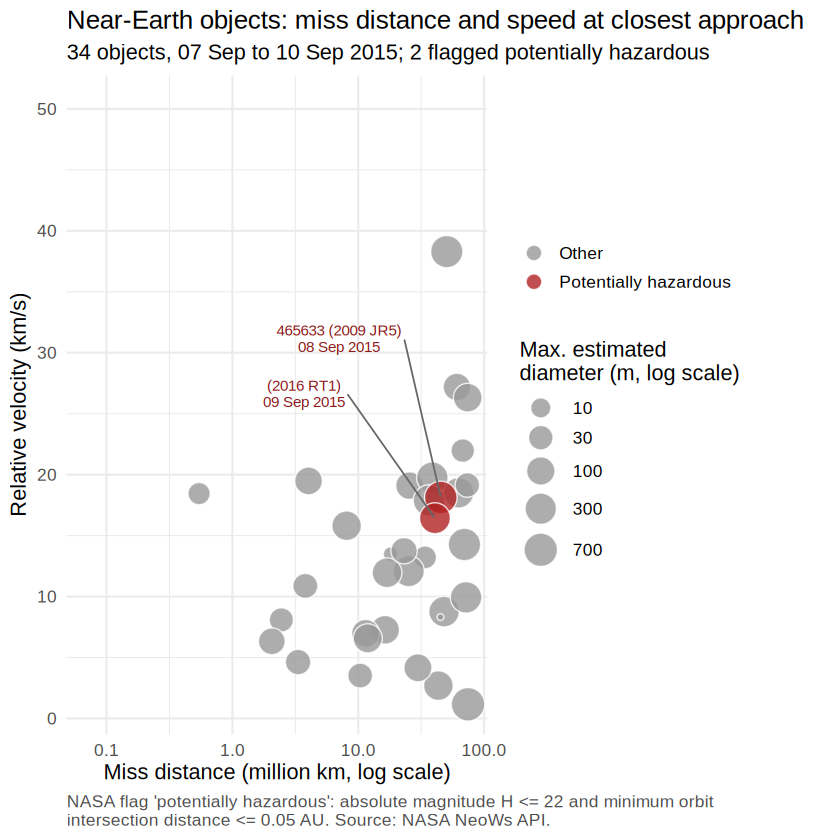

In [ ]:
plot_df <- asteroid_df |>
  mutate(
    distance_mio_km = miss_distance_km / 1e6,
    label = if_else(hazardous, paste0(name, "\n", format(date, "%d %b %Y")), NA_character_)
  ) |>
  arrange(hazardous)            # draw hazardous objects last, so they sit on top

ggplot(plot_df, aes(x = distance_mio_km, y = velocity_km_s)) +
  geom_point(aes(size = diameter_max_m, fill = hazardous),
             shape = 21, colour = "white", stroke = 0.6, alpha = 0.8) +
  geom_text_repel(aes(label = label), na.rm = TRUE,
                  size = 3.2, lineheight = 0.9, colour = "firebrick4",
                  nudge_x = -0.9, nudge_y = 12, box.padding = 0.6,
                  segment.colour = "grey40", min.segment.length = 0, seed = 1) +
  scale_x_log10(labels = scales::label_number()) +
  scale_fill_manual(values = c("FALSE" = "grey60", "TRUE" = "firebrick"),
                    labels = c("FALSE" = "Other", "TRUE" = "Potentially hazardous")) +
  scale_size_continuous(range = c(1.5, 9), transform = "log10",
                        breaks = c(10, 30, 100, 300, 700)) +
  guides(fill = guide_legend(order = 1, override.aes = list(size = 4)),
         size = guide_legend(order = 2, override.aes = list(fill = "grey60"))) +
  labs(
    title    = "Near-Earth objects: miss distance and speed at closest approach",
    subtitle = paste0(nrow(plot_df), " objects, ", format(as.Date(start_date), "%d %b"), " to ",
                      format(as.Date(end_date), "%d %b %Y"), "; ",
                      sum(plot_df$hazardous), " flagged potentially hazardous"),
    x = "Miss distance (million km, log scale)",
    y = "Relative velocity (km/s)",
    fill = NULL,
    size = "Max. estimated\ndiameter (m, log scale)",
    caption = paste("NASA flag 'potentially hazardous': absolute magnitude H <= 22 and minimum orbit",
                    "intersection distance <= 0.05 AU. Source: NASA NeoWs API.", sep = "\n")
  ) +
  theme_minimal(base_size = 13) +
  theme(plot.caption = element_text(hjust = 0, colour = "grey30"))